# 운영 지표와 Ch18 궤적 비교

**이 노트북에서 할 일**

1. Ch 18 06절 노트북에 저장된 출력과 Ch 21 06절의 비교 기록 파일을 읽기만 합니다.
2. 두 기록의 줄을 같은 칸 이름의 딕셔너리로 옮겨 담고, 요청 수와 성공 여부를 셉니다.
3. 칸마다 평균과 95 백분위수를 보고, 줄이 셋이면 95 백분위수가 가장 큰 값이 되는 까닭을 셉니다.

**준비물** — 이 노트북은 모델을 부르지 않아 API 키가 필요 없습니다.
모델 요청은 0번이고, 요금도 들지 않습니다.
읽는 파일은 앞 챕터 파일 둘과 같은 폴더의 도구 파일 `eval_tools.py`이고, 쓰는 파일은 없습니다.
두 파일은 Ch 18 06절과 Ch 21 06절을 한 번 실행해 남긴 기록이고, 이 노트북은 두 절을 다시 실행하지 않습니다.
이 노트북은 걸린 시간을 재지 않고, 기록에 적힌 걸린 초를 읽기만 합니다.

**기준 버전** — 첫 셀에서 패키지 하나를 설치합니다.
판은 langchain 1.4.0이고, 도구 파일이 메시지 클래스를 가져올 때 씁니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
두 기록을 찾아 읽고, 같은 칸 이름으로 옮겨 담아 세는 자리입니다.
6~8절은 평균과 95 백분위수를 보고 백분위 하나를 바꿔 보는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch29-agent-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 둘은 앞 챕터가 남긴 기록입니다. 왼쪽 상자는 Ch 18 06절 노트북에 저장된 비교 표 다섯 줄로, 칸 calls·tokens·latency_s·quality/5·status가 있습니다. 오른쪽 상자는 Ch 21 06절 비교 기록 파일로, 질문 세 줄에 칸 열둘이 있고 model_calls·tool_calls·agent_latency_s 등이 적혀 있습니다. 왼쪽 상자는 파란 상자 ch18_row, 도구 요청 수는 None, 점수는 품질 ÷ 5로 이어집니다. 오른쪽 상자는 파란 상자 ch21_row, 점수는 평가 모델 판정, 참이면 1.0으로 이어집니다. 두 파란 상자는 맨 아래 노란 상자 공통 칸 표 여덟 줄로 모이고, 칸은 이름·요청 수·도구 요청 수·토큰 수·걸린 초·점수인 그림](attachment:04-1-두-기록을-같은-칸으로.png)

위에서 아래로 읽습니다.
초록 상자 둘은 앞 챕터가 남긴 기록이고, 파란 상자 둘은 이 노트북 4절에서 정의한 함수입니다.
노란 상자는 4절에서 출력한 공통 칸 표입니다.
Ch 18 쪽 도구 요청 수는 기록에 칸이 없어 None으로 두었습니다.
칸 점수는 두 기록의 잣대가 서로 달라, 두 쪽을 견주지 않습니다.
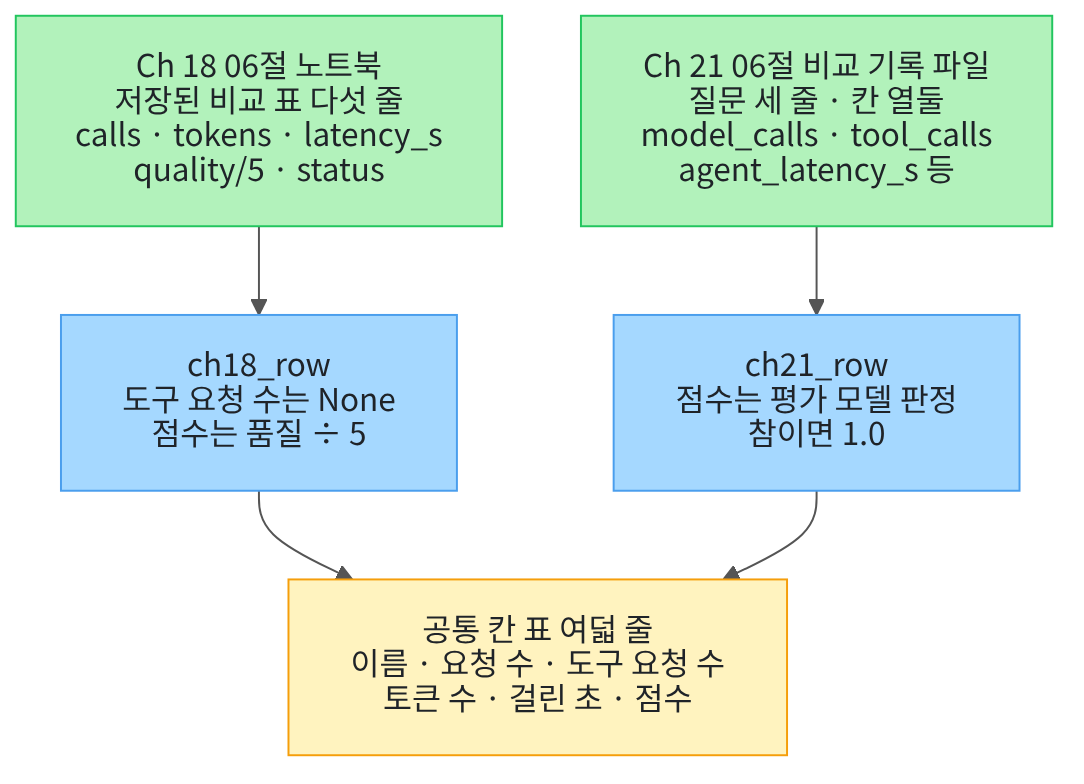

## 1. 준비

01~03절은 궤적 하나를 코드 규칙과 평가 모델로 판정했습니다.
이 절은 모델을 부르지 않고, 앞 챕터가 남긴 실행 기록 두 개를 읽어 운영 지표를 견줍니다.
뜻과 구성은 본문 「핵심 개념」에서 풉니다.

첫 셀은 패키지 하나를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0"
from importlib.metadata import version

print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0


**결과 읽기** — 출력 줄 `langchain: 1.4.0`이 보입니다.
실습 폴더 잠금과 같은 판입니다.
이 노트북의 셀은 langchain을 직접 쓰지 않습니다.
도구 파일 `eval_tools.py`가 맨 위에서 메시지 클래스를 가져오기 때문에 설치합니다.

다음 셀은 이 절에서 쓸 모듈과 함수를 가져옵니다.
모듈 `json`과 `os`는 Ch 21 06절처럼 파일을 찾고 읽을 때 씁니다.
모듈 `math`의 함수 `math.ceil`은 Ch 15 06절에서 본 올림 함수입니다.

In [2]:
# 기록 파일을 찾고 읽는 모듈 둘과, 올림 함수 ceil이 든 모듈 math(Ch 15 06절)를 가져옵니다
import json
import math
import os
# 앞에서 배운 함수는 도구 파일에서 가져옵니다
from eval_tools import average, nearest_rank

print("도구 파일에서 가져온 함수:", "average, nearest_rank")

도구 파일에서 가져온 함수: average, nearest_rank


**결과 읽기** — 라벨 `도구 파일에서 가져온 함수:` 뒤에 `average`와 `nearest_rank`가 보입니다.
앞에서 배운 함수는 `eval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.

노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

두 함수는 Ch 15 06절 노트북에서 배웠고, 이 절부터 도구 파일에서 가져옵니다.
도구 파일에는 그 노트북 셀의 주석과 본문을 글자 그대로 옮겼고, 인자도 같습니다.
함수 `average(values)`는 값 목록의 평균을 소수 여섯째 자리까지 냅니다.
함수 `nearest_rank(values, percent)`는 가장 가까운 자리 방식으로 백분위수 하나를 냅니다.

## 2. 두 기록 파일 찾기

이 절이 읽는 기록은 둘입니다.
하나는 Ch 18 06절 노트북에 저장된 비교 표 출력이고, 다른 하나는 Ch 21 06절이 쓴 비교 기록 파일입니다.
두 파일은 다른 챕터 폴더에 있어, 다음 셀은 먼저 프로젝트 맨 위 폴더를 찾습니다.
셀 모양은 Ch 21 06절의 자리 찾기 셀과 같고, 확인하는 폴더만 다릅니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part6/ch21-create-agent/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구가 프로젝트 맨 위 폴더에서 커널을 띄운 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
학생 묶음을 풀어 `notebooks/` 폴더에서 열어도 같은 자리를 찾습니다.

다음 셀은 두 기록 파일의 자리를 만들고, 파일이 있는지 봅니다.

In [4]:
# 두 기록 파일의 자리를 만들고, 둘 다 있는지 봅니다(두 파일은 읽기만 하고 고치지 않습니다)
ch18_path = root_path + "/labs/part5/ch18-workflow-patterns/notebooks/06-같은-과제로-다섯-패턴-비교.ipynb"
ch21_path = root_path + "/labs/part6/ch21-create-agent/data/rag-comparison.json"
print("Ch 18 06절 노트북이 있는가:", os.path.exists(ch18_path))
print("Ch 21 06절 비교 기록이 있는가:", os.path.exists(ch21_path))

Ch 18 06절 노트북이 있는가: True
Ch 21 06절 비교 기록이 있는가: True


**결과 읽기** — 출력 줄 `Ch 18 06절 노트북이 있는가: True`와 `Ch 21 06절 비교 기록이 있는가: True`가 보입니다.
두 파일 모두 이 자리에 있습니다.

## 3. Ch 18 기록: 저장된 출력에서 표 줄 찾기

Ch 18 06절은 같은 과제를 다섯 흐름으로 실행하고, 비교 표를 출력했습니다.
표의 칸은 패턴·요청 수·토큰 수·걸린 초·품질·상태 여섯입니다.
이 표에는 도구를 부른 차례가 없습니다.
Ch 18의 다섯 흐름은 도구 호출 요청을 쓰지 않았기 때문입니다.
그래서 Ch 18 줄은 궤적이 아니라, 흐름 하나를 실행한 기록 한 줄로 읽습니다.

노트북 파일(`.ipynb`)은 셀의 글과 저장된 출력을 담은 JSON 파일입니다.
다음 셀은 Ch 18 06절 노트북 파일을 JSON으로 읽고, 셀 수를 봅니다.
그 노트북은 실행하지 않습니다.

In [5]:
# Ch 18 06절 노트북 파일을 JSON으로 읽습니다(그 노트북은 실행하지 않고, 저장된 출력만 씁니다)
with open(ch18_path, encoding="utf-8") as file:
    ch18_notebook = json.loads(file.read())
print("셀 수:", len(ch18_notebook["cells"]))

셀 수: 58


**결과 읽기** — 출력 줄 `셀 수: 58`이 보입니다.
비교 표는 그 가운데 한 코드 셀의 저장된 출력에 있습니다.
이 절이 읽는 비교 표는 Ch 18 06절을 한 번 실행해 저장한 출력입니다.

셀마다 저장된 출력은 칸 `outputs`의 목록에 있습니다.
출력 가운데 `print`로 찍힌 글은 칸 `output_type`이 `stream`이고, 글은 칸 `text`에 줄 목록으로 들어 있습니다.
다음 셀은 코드 셀 하나에서 이 글만 모아 한 줄씩 내놓는 함수를 정의합니다.
글 메서드 `join`(Ch 16 01절)으로 줄 목록을 한 글로 잇고, `splitlines`(03절)로 다시 줄마다 나눕니다.

In [6]:
# 코드 셀 하나의 저장된 출력 가운데 print로 찍힌 글(stream)만 한 줄씩 나눠 목록으로 내놓습니다
def printed_lines_of(cell):
    lines = []
    for output in cell["outputs"]:
        if output["output_type"] == "stream":
            printed_text = "".join(output["text"])
            for line in printed_text.splitlines():
                lines.append(line)
    return lines

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `printed_lines_of(cell)`는 코드 셀 하나를 받아, `print`로 찍힌 줄의 목록을 내놓습니다.

다음 셀은 이 함수로 노트북의 모든 코드 셀에서 저장된 출력 줄을 모읍니다.
마크다운 셀에는 칸 `outputs`가 없어, 칸 `cell_type`이 `code`인 셀만 봅니다.

In [7]:
# 코드 셀마다 저장된 출력 줄을 모두 모읍니다(마크다운 셀에는 출력이 없어 건너뜁니다)
printed_lines = []
for cell in ch18_notebook["cells"]:
    if cell["cell_type"] == "code":
        for line in printed_lines_of(cell):
            printed_lines.append(line)
print("저장된 출력 줄 수:", len(printed_lines))

저장된 출력 줄 수: 69


**결과 읽기** — 출력 줄 `저장된 출력 줄 수: 69`가 보입니다.
Ch 18 06절 노트북의 코드 셀들이 찍은 줄을 모두 모은 수입니다.

비교 표 줄은 칸을 「 | 」로 나눠 찍었습니다.
표 맨 위의 머리 줄은 `pattern`으로 시작해, 표 줄에서 뺍니다.
다음 셀은 「 | 」가 든 줄 가운데 머리 줄이 아닌 줄만 모읍니다.
03절에서 쓴 글 메서드 `startswith`로 머리 줄을 가립니다.

In [8]:
# 칸 구분 「 | 」가 든 줄 가운데 머리 줄(pattern으로 시작)을 뺀 표 줄만 모읍니다
table_lines = []
for line in printed_lines:
    if " | " in line:
        if not line.startswith("pattern"):
            table_lines.append(line)
print("표 줄 수:", len(table_lines))
assert len(table_lines) >= 5, "Ch 18 06절 노트북에 저장된 비교 표가 다섯 줄보다 적습니다."

표 줄 수: 5


**결과 읽기** — 출력 줄 `표 줄 수: 5`가 보이고, `assert`도 오류 없이 지나갔습니다.
Ch 18 06절 표의 다섯 흐름이 한 줄씩입니다.

다음 셀은 표 줄 가운데 마지막 다섯 줄을 Ch 18 기록으로 씁니다.
비교 표는 Ch 18 06절 노트북의 뒤쪽에서 한 번 찍히므로, 마지막 다섯 줄이 그 표입니다.
번호 `[-5:]`는 Ch 16 03절에서 본 음수 슬라이스로, 끝에서 다섯 개를 자릅니다.

In [9]:
# 표 줄 가운데 마지막 다섯 줄을 Ch 18 다섯 흐름의 기록으로 씁니다(칸: 패턴·요청 수·토큰 수·걸린 초·품질·상태)
ch18_lines = table_lines[-5:]
print("Ch 18 표 다섯 줄:")
for line in ch18_lines:
    print(line)

Ch 18 표 다섯 줄:
chaining | 2 | 712 | 3.756 | 5 | ok
routing | 2 | 503 | 2.746 | 5 | ok
parallel | 3 | 676 | 1.043 | 4 | ok
orchestrator_worker | 5 | 1790 | 6.519 | 5 | ok
generator_evaluator | 2 | 630 | 6.966 | 5 | ok


**결과 읽기** — 라벨 줄 `Ch 18 표 다섯 줄:` 아래 다섯 줄이 보입니다.
첫 줄은 `chaining | 2 | 712 | 3.756 | 5 | ok`이고, 마지막 줄은 `generator_evaluator`로 시작합니다.

줄마다 차례대로 패턴 이름·요청 수·토큰 수·걸린 초·품질·상태입니다.
요청 수는 모델 요청 수이고, 토큰 수는 입력 토큰과 출력 토큰을 더한 값입니다.
품질은 안내문을 코드로 검사해 센 0~5이고, 평가 모델의 점수가 아닙니다.

## 4. 공통 칸으로 옮겨 담기

두 기록은 칸 이름이 다릅니다.
Ch 18 표의 `calls`와 Ch 21 기록의 `model_calls`는 이름이 다르지만, 둘 다 모델 요청 수입니다.
이런 값을 같은 이름의 칸으로 옮겨 담으면, 두 기록을 한 표에 모을 수 있습니다.
이렇게 맞춘 칸을 이 절에서는 공통 칸이라고 부릅니다.
공통 칸은 이름·요청 수·도구 요청 수·토큰 수·걸린 초·점수 여섯입니다.

다음 셀은 표 줄 하나를 칸 여섯으로 나누는 함수를 정의합니다.
글 메서드 `split`으로 「|」에서 나누고, `strip`으로 칸마다 앞뒤 빈칸을 뺍니다.

In [10]:
# 표 줄 하나를 「|」로 나누고, 칸마다 앞뒤 빈칸을 뺀 글을 목록으로 내놓습니다
def split_row(line):
    parts = []
    for part in line.split("|"):
        parts.append(part.strip())
    return parts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `split_row(line)`는 표 줄 하나를 받아, 글 여섯 개의 목록을 내놓습니다.

다음 셀은 나눈 칸 여섯을 공통 칸 딕셔너리로 옮겨 담는 함수를 정의합니다.
Ch 18 기록에는 도구 요청 수 칸이 없어, 그 칸은 모르는 값 `None`으로 둡니다.
점수는 품질을 만점으로 나눠 0~1로 맞추고, 만점은 인자 `full_quality`로 받습니다.

In [11]:
# 나눈 Ch 18 표 줄 하나를 공통 칸 딕셔너리로 옮겨 담아 내놓습니다(도구 요청 수는 기록에 없어 None)
def ch18_row(parts, full_quality):
    return {
        "이름": "Ch 18 " + parts[0],
        "요청 수": int(parts[1]),
        "도구 요청 수": None,
        "토큰 수": int(parts[2]),
        "걸린 초": float(parts[3]),
        "점수": int(parts[4]) / full_quality,
    }

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ch18_row(parts, full_quality)`는 나눈 칸 목록과 품질 만점을 받아, 공통 칸 딕셔너리 하나를 내놓습니다.
요청 수·토큰 수·품질은 `int`로, 걸린 초는 `float`로 바꿔 숫자로 담습니다.

다음 셀은 Ch 18 다섯 줄을 모두 옮겨 담고, 상태 칸이 `ok`인 줄을 셉니다.
품질 만점은 코드 검사 항목 수 5입니다.
다섯 흐름이 모두 끝까지 갔는지는 기록의 모양이라 `assert`로 확인합니다.

In [12]:
# Ch 18 다섯 줄을 공통 칸으로 옮겨 담고, 상태 칸이 ok인 줄을 셉니다(품질 칸의 만점은 코드 검사 다섯 항목)
full_quality = 5
ch18_rows = []
ok_count = 0
for line in ch18_lines:
    parts = split_row(line)
    ch18_rows.append(ch18_row(parts, full_quality))
    if parts[5] == "ok":
        ok_count = ok_count + 1
print("옮겨 담은 줄 수:", len(ch18_rows), "| 상태가 ok인 줄 수:", ok_count)
assert ok_count == len(ch18_rows), "Ch 18 표에 상태가 ok가 아닌 줄이 있습니다."

옮겨 담은 줄 수: 5 | 상태가 ok인 줄 수: 5


**결과 읽기** — 출력 줄 `옮겨 담은 줄 수: 5 | 상태가 ok인 줄 수: 5`가 보이고, `assert`도 지나갔습니다.
다섯 흐름 모두 상태가 `ok`였습니다.

이제 Ch 21 기록을 읽습니다.
Ch 21 06절은 질문 세 개를 고정 흐름과 에이전트 흐름으로 견주고, 질문마다 비교 기록 한 줄을 파일에 썼습니다.
이 절은 그 가운데 에이전트 흐름의 칸만 읽습니다.
다음 셀은 파일을 읽고, 줄 수와 질문 번호를 봅니다.

In [13]:
# Ch 21 06절이 쓴 비교 기록 파일을 읽고, 줄 수·한 줄의 칸 수·질문 번호를 봅니다
with open(ch21_path, encoding="utf-8") as file:
    ch21_records = json.loads(file.read())
qids = []
for record in ch21_records:
    qids.append(record["qid"])
print("줄 수:", len(ch21_records), "| 한 줄의 칸 수:", len(ch21_records[0]))
print("질문 번호:", qids)
assert len(ch21_records) == 3, "Ch 21 비교 기록은 질문 세 줄이어야 합니다."

줄 수: 3 | 한 줄의 칸 수: 12
질문 번호: ['C01', 'C05', 'C07']


**결과 읽기** — 출력 줄 `줄 수: 3 | 한 줄의 칸 수: 12`와 `질문 번호: ['C01', 'C05', 'C07']`이 보입니다.
줄이 셋이라 `assert`도 지나갔습니다.

한 줄의 칸 열둘 가운데 이 절은 여섯을 읽습니다.
질문 번호 `qid`, 사용량 `agent_usage`, 도구 요청 수 `tool_calls`, 걸린 초 `agent_latency_s`가 그 가운데 넷입니다.
나머지 둘은 평가 모델 판정 `agent_supported`와 검색 기록 `agent_trace`입니다.
다음 셀은 한 줄을 공통 칸 딕셔너리로 옮겨 담는 함수를 정의합니다.
참·거짓 값에 `float`를 쓰면, 참은 `1.0`이 되고 거짓은 `0.0`이 됩니다.

In [14]:
# Ch 21 비교 기록 한 줄을 공통 칸 딕셔너리로 옮겨 담아 내놓습니다(점수는 평가 모델 판정 — 참이면 1.0)
def ch21_row(record):
    return {
        "이름": "Ch 21 " + record["qid"],
        "요청 수": record["agent_usage"]["model_calls"],
        "도구 요청 수": record["tool_calls"],
        "토큰 수": record["agent_usage"]["input_tokens"] + record["agent_usage"]["output_tokens"],
        "걸린 초": record["agent_latency_s"],
        "점수": float(record["agent_supported"]),
    }

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ch21_row(record)`는 비교 기록 한 줄을 받아, 공통 칸 딕셔너리 하나를 내놓습니다.
토큰 수는 입력 토큰과 출력 토큰을 더해, Ch 18 표의 토큰 수와 같은 뜻으로 맞춥니다.

다음 셀은 세 줄을 모두 옮겨 담습니다.
Ch 21 06절은 이 파일의 줄마다 도구 요청 수가 1 이상이라고 적어 두었습니다.
그래서 줄마다 이 값을 `assert`로 확인합니다.

In [15]:
# Ch 21 세 줄을 공통 칸으로 옮겨 담고, 줄마다 도구 요청 수가 1 이상인지 확인합니다
ch21_rows = []
for record in ch21_records:
    ch21_rows.append(ch21_row(record))
    assert record["tool_calls"] >= 1, "도구를 부르지 않은 줄이 있습니다."
print("옮겨 담은 줄 수:", len(ch21_rows))
print("첫 줄:", ch21_rows[0])

옮겨 담은 줄 수: 3
첫 줄: {'이름': 'Ch 21 C01', '요청 수': 2, '도구 요청 수': 1, '토큰 수': 684, '걸린 초': 1.829, '점수': 1.0}


**결과 읽기** — 출력 줄 `옮겨 담은 줄 수: 3`이 보이고, `assert`도 세 줄 모두 지나갔습니다.
라벨 `첫 줄:` 뒤 딕셔너리의 칸 `'요청 수': 2`와 `'도구 요청 수': 1`이 보입니다.

다음 셀은 공통 칸 딕셔너리 한 줄을 표 한 줄로 출력하는 함수를 정의합니다.
Ch 18 줄과 Ch 21 줄에 같은 함수를 씁니다.

In [16]:
# 공통 칸 딕셔너리 한 줄을 「|」로 이은 표 한 줄로 출력합니다(내놓는 값 없음)
def show_row(row):
    print(row["이름"], "|", row["요청 수"], "|", row["도구 요청 수"], "|", row["토큰 수"], "|", row["걸린 초"], "|", row["점수"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `show_row(row)`는 칸 여섯을 「|」로 이어 한 줄로 출력하고, 내놓는 값은 없습니다.

다음 셀은 두 기록의 여덟 줄을 공통 칸 표 하나로 출력합니다.
표 하나에 모아도, 두 기록의 과제와 조건은 서로 다릅니다.

In [17]:
# 두 기록의 여덟 줄을 공통 칸 표 하나로 출력합니다(걸린 초와 토큰 수는 각 기록이 한 번 실행한 값)
print("이름 | 요청 수 | 도구 요청 수 | 토큰 수 | 걸린 초 | 점수")
for row in ch18_rows:
    show_row(row)
for row in ch21_rows:
    show_row(row)

이름 | 요청 수 | 도구 요청 수 | 토큰 수 | 걸린 초 | 점수
Ch 18 chaining | 2 | None | 712 | 3.756 | 1.0
Ch 18 routing | 2 | None | 503 | 2.746 | 1.0
Ch 18 parallel | 3 | None | 676 | 1.043 | 0.8
Ch 18 orchestrator_worker | 5 | None | 1790 | 6.519 | 1.0
Ch 18 generator_evaluator | 2 | None | 630 | 6.966 | 1.0
Ch 21 C01 | 2 | 1 | 684 | 1.829 | 1.0
Ch 21 C05 | 2 | 1 | 681 | 1.36 | 1.0
Ch 21 C07 | 2 | 1 | 699 | 2.003 | 1.0


**결과 읽기** — 라벨 줄 `이름 | 요청 수 | 도구 요청 수 | 토큰 수 | 걸린 초 | 점수` 아래 여덟 줄이 보입니다.
Ch 18 다섯 줄은 `Ch 18 chaining | 2 | None`처럼 도구 요청 수가 `None`입니다.
Ch 21 세 줄은 `Ch 21 C01 | 2 | 1`처럼 요청 수 2, 도구 요청 수 1입니다.

토큰 수와 걸린 초는 각 기록이 한 번 실행한 값입니다.
교재 출력에서는 Ch 18 걸린 초가 `1.043`부터 `6.966`까지, Ch 21 걸린 초가 `1.36`부터 `2.003`까지였습니다.
두 기록은 과제·질문·요청을 보낸 방법이 달라, 이 값으로 어느 쪽이 낫다고 정하지 않습니다.
점수 칸도 Ch 18은 코드 검사, Ch 21은 평가 모델 판정이라 잣대가 다릅니다.

## 5. 세는 값으로 읽기

03절에서 본 것처럼, 에이전트의 모델 요청 수는 「도구를 요청한 응답 수 + 1」입니다.
Ch 21 기록의 칸 `tool_calls`는 도구 메시지 수입니다.
도구 메시지가 하나이면, 도구를 요청한 응답도 하나입니다.
다음 셀은 이 셈이 세 줄에 맞는지 보고, 칸 `agent_trace`에 든 검색 기록 수도 셉니다.

In [18]:
# 03절의 요청 수 셈(도구를 요청한 응답 수 + 1)이 Ch 21 세 줄에 맞는지, 검색 기록 수도 함께 봅니다
print("질문 | 요청 수 | 도구 요청 수 | 요청 수 = 도구 요청 수 + 1 | 검색 기록 수")
for record in ch21_records:
    calls = record["agent_usage"]["model_calls"]
    tools = record["tool_calls"]
    searches = len(record["agent_trace"])
    print(record["qid"], "|", calls, "|", tools, "|", calls == tools + 1, "|", searches)

질문 | 요청 수 | 도구 요청 수 | 요청 수 = 도구 요청 수 + 1 | 검색 기록 수
C01 | 2 | 1 | True | 1
C05 | 2 | 1 | True | 1
C07 | 2 | 1 | True | 1


**결과 읽기** — 라벨 줄 아래 세 줄 `C01 | 2 | 1 | True | 1`, `C05 | 2 | 1 | True | 1`, `C07 | 2 | 1 | True | 1`이 보입니다.
세 줄 모두 요청 수가 도구 요청 수에 1을 더한 값과 같았습니다.
검색 기록 수도 줄마다 1로, 도구 요청 수와 같았습니다.

요청 수는 도구를 요청한 응답 하나와 답을 쓴 응답 하나를 더한 2입니다.
03절의 에이전트는 도구 둘을 차례로 불러 요청이 3번이었고, 이 기록은 도구 하나라 2번입니다.
도구를 한 번 부른 것은 Ch 21 06절의 실행에서 모델이 고른 일이라, 그 절을 다시 실행하면 달라질 수 있습니다.

다음 셀은 두 기록이 잘됐다고 적은 줄을 셉니다.
Ch 18은 상태 칸과 품질 칸, Ch 21은 평가 모델 판정으로 셉니다.

In [19]:
# 두 기록이 잘됐다고 적은 줄을 기록마다 제 잣대로 셉니다(Ch 18은 상태·품질 칸, Ch 21은 평가 모델 판정)
full_count = 0
for row in ch18_rows:
    if row["점수"] == 1.0:
        full_count = full_count + 1
supported_count = 0
for record in ch21_records:
    if record["agent_supported"]:
        supported_count = supported_count + 1
print("Ch 18 상태가 ok인 줄:", ok_count, "| 품질이 만점인 줄:", full_count, "| 전체:", len(ch18_rows))
print("Ch 21 평가 모델 판정이 참인 줄:", supported_count, "| 전체:", len(ch21_rows))

Ch 18 상태가 ok인 줄: 5 | 품질이 만점인 줄: 4 | 전체: 5
Ch 21 평가 모델 판정이 참인 줄: 3 | 전체: 3


**결과 읽기** — 출력 줄 `Ch 18 상태가 ok인 줄: 5 | 품질이 만점인 줄: 4 | 전체: 5`가 보입니다.
출력 줄 `Ch 21 평가 모델 판정이 참인 줄: 3 | 전체: 3`도 보입니다.

Ch 18 상태 칸은 흐름이 끝까지 갔는지, 품질 칸은 안내문이 코드 검사를 몇 항목 지났는지입니다.
Ch 21 판정은 답이 준 문서로 뒷받침되는지를 평가 모델이 Ch 21 06절에서 한 번 본 값입니다.
세 값 모두 「잘됐다」를 세지만 잣대가 서로 달라, 줄 수를 두 기록 사이에서 견주지 않습니다.

## 6. 칸마다 평균

다음 셀은 공통 칸 딕셔너리 목록에서 칸 하나의 값만 모으는 함수를 정의합니다.
이 목록을 Ch 15 06절 함수 `average`와 `nearest_rank`에 넘깁니다.

In [20]:
# 공통 칸 딕셔너리 목록에서 칸 이름 하나의 값만 차례대로 모아 목록으로 내놓습니다
def column_values(rows, key):
    values = []
    for row in rows:
        values.append(row[key])
    return values

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `column_values(rows, key)`는 딕셔너리 목록과 칸 이름을 받아, 그 칸의 값 목록을 내놓습니다.

다음 셀은 Ch 18 다섯 줄에서 칸마다 평균을 냅니다.
도구 요청 수 칸은 `None`이라 평균을 내지 않습니다.
기록의 걸린 초가 소수 셋째 자리까지라, `round`로 평균도 셋째 자리까지 남깁니다.

In [21]:
# Ch 18 다섯 줄에서 칸마다 값을 모아 평균을 냅니다(Ch 15 06절 함수 average, 소수 셋째 자리까지)
print("Ch 18 다섯 줄의 평균:")
for key in ["요청 수", "점수", "토큰 수", "걸린 초"]:
    values = column_values(ch18_rows, key)
    mean_value = round(average(values), 3)
    print(key, "|", mean_value)

Ch 18 다섯 줄의 평균:
요청 수 | 2.8
점수 | 0.96
토큰 수 | 862.2
걸린 초 | 4.206


**결과 읽기** — 라벨 줄 `Ch 18 다섯 줄의 평균:` 아래 네 줄이 보입니다.
출력 줄 `요청 수 | 2.8`과 `점수 | 0.96`이 보입니다.
요청 수 합 14를 다섯 흐름으로 나눈 값이고, 점수는 다섯 줄 가운데 넷이 만점이라 0.96입니다.

교재 출력에서는 `토큰 수 | 862.2`, `걸린 초 | 4.206`이었습니다.
두 값은 Ch 18 06절을 한 번 실행한 값이라, 그 절을 다시 실행하면 달라집니다.

다음 셀은 Ch 21 세 줄에서 같은 칸마다 평균을 냅니다.
도구 요청 수 칸도 함께 봅니다.

In [22]:
# Ch 21 세 줄에서도 칸마다 평균을 냅니다(도구 요청 수 칸은 이 기록에만 있습니다)
print("Ch 21 세 줄의 평균:")
for key in ["요청 수", "도구 요청 수", "점수", "토큰 수", "걸린 초"]:
    values = column_values(ch21_rows, key)
    mean_value = round(average(values), 3)
    print(key, "|", mean_value)

Ch 21 세 줄의 평균:
요청 수 | 2.0
도구 요청 수 | 1.0
점수 | 1.0
토큰 수 | 688.0
걸린 초 | 1.731


**결과 읽기** — 라벨 줄 `Ch 21 세 줄의 평균:` 아래 다섯 줄이 보입니다.
출력 줄 `요청 수 | 2.0`과 `도구 요청 수 | 1.0`, `점수 | 1.0`이 보입니다.
세 줄의 값이 모두 같아, 평균도 그 값입니다.

교재 출력에서는 `토큰 수 | 688.0`, `걸린 초 | 1.731`이었습니다.
두 값도 Ch 21 06절을 한 번 실행한 값입니다.
Ch 18 평균과 나란히 놓아도, 과제가 달라 어느 쪽이 빠르거나 적다고 읽지 않습니다.

## 7. 95 백분위수

평균만으로는 오래 걸린 실행이 있었는지 알기 어렵습니다.
Ch 15 06절에서는 값을 줄 세워 95번째 백분위수를 봤습니다.
가장 가까운 자리 방식에서 자리는 95 × 줄 수 ÷ 100을 올린 정수이고, 줄 세운 값에서 그 자리의 값을 고릅니다.

다음 셀은 Ch 21 세 줄의 걸린 초와 토큰 수로 이 자리와 값을 봅니다.
실행 전에 예상해 봅니다. 줄이 셋이면 95 백분위수는 몇 번째 자리일까요?

In [23]:
# Ch 21 세 줄의 걸린 초와 토큰 수를 줄 세워 보고, 95 백분위수를 찾습니다(Ch 15 06절 함수 nearest_rank)
percent = 95
ch21_seconds = column_values(ch21_rows, "걸린 초")
ch21_tokens = column_values(ch21_rows, "토큰 수")
rank = math.ceil(percent * len(ch21_seconds) / 100)
print("95 백분위수 자리:", rank, "| 줄 수:", len(ch21_seconds))
print("줄 세운 걸린 초:", sorted(ch21_seconds))
print("95 백분위수 걸린 초:", nearest_rank(ch21_seconds, percent))
print("줄 세운 토큰 수:", sorted(ch21_tokens))
print("95 백분위수 토큰 수:", nearest_rank(ch21_tokens, percent))

95 백분위수 자리: 3 | 줄 수: 3
줄 세운 걸린 초: [1.36, 1.829, 2.003]
95 백분위수 걸린 초: 2.003
줄 세운 토큰 수: [681, 684, 699]
95 백분위수 토큰 수: 699


**결과 읽기** — 출력 줄 `95 백분위수 자리: 3 | 줄 수: 3`이 보입니다.
95 × 3 ÷ 100 = 2.85를 올리면 3이라, 줄 세운 세 값 가운데 세 번째, 곧 가장 큰 값입니다.

교재 출력에서는 라벨 `줄 세운 걸린 초:` 뒤가 `[1.36, 1.829, 2.003]`이었습니다.
그래서 `95 백분위수 걸린 초: 2.003`이었고, 토큰 수도 가장 큰 값 `699`였습니다.
두 값은 Ch 21 06절을 한 번 실행한 값입니다.

줄이 셋일 때만 이런지 궁금합니다.
다음 셀은 같은 셈을 줄 수만 바꿔, 95 백분위수가 가장 큰 값의 자리인지 봅니다.

In [24]:
# 줄 수마다 95 백분위수가 몇 번째 자리인지 셉니다(자리 = 95 × 줄 수 ÷ 100을 올린 정수)
print("줄 수 | 95 백분위수 자리 | 가장 큰 값의 자리인가")
for row_count in [3, 5, 19, 20, 100]:
    rank = math.ceil(percent * row_count / 100)
    print(row_count, "|", rank, "|", rank == row_count)

줄 수 | 95 백분위수 자리 | 가장 큰 값의 자리인가
3 | 3 | True
5 | 5 | True
19 | 19 | True
20 | 19 | False
100 | 95 | False


**결과 읽기** — 라벨 줄 아래 다섯 줄이 보입니다.
줄 `3 | 3 | True`, `5 | 5 | True`, `19 | 19 | True`는 자리가 줄 수와 같았습니다.
줄 `20 | 19 | False`부터는 가장 큰 값이 아닌 자리를 골랐습니다.

줄이 열아홉 이하이면 95 백분위수는 늘 가장 큰 값입니다.
그래서 줄이 적은 기록의 95 백분위수는 가장 큰 값 하나를 다시 읽는 것과 같습니다.
오래 걸린 실행이 얼마나 드문지 보려면, 같은 서비스의 실행을 훨씬 많이 모아야 합니다.

## 8. 값 바꿔 보기: 백분위 하나만 바꾸기

이제 값 하나만 바꿔 봅니다.
바꿀 값은 백분위이고, 95를 50으로 바꿉니다.
줄 수와 값 목록은 그대로 둡니다.
실행 전에 예상해 봅니다. 줄 셋에서 50 백분위수는 몇 번째 자리일까요?

In [25]:
# 값 바꿔 보기: 백분위 하나만 95에서 50으로 바꿔, 같은 세 줄에서 자리와 값을 봅니다
changed_percent = 50
changed_rank = math.ceil(changed_percent * len(ch21_seconds) / 100)
print("50 백분위수 자리:", changed_rank)
print("50 백분위수 걸린 초:", nearest_rank(ch21_seconds, changed_percent))
print("50 백분위수 토큰 수:", nearest_rank(ch21_tokens, changed_percent))

50 백분위수 자리: 2
50 백분위수 걸린 초: 1.829
50 백분위수 토큰 수: 684


**결과 읽기** — 출력 줄 `50 백분위수 자리: 2`가 보입니다.
50 × 3 ÷ 100 = 1.5를 올린 2라, 줄 세운 세 값의 가운데 값입니다.

교재 출력에서는 `50 백분위수 걸린 초: 1.829`, `50 백분위수 토큰 수: 684`였습니다.
95 백분위수와 달리 가장 큰 값이 아닌 가운데 값이 나왔습니다.
백분위를 바꾸면 자리가 바뀌고, 자리가 바뀌면 고르는 값이 바뀝니다.

## 정리

1. 두 기록의 여덟 줄을 공통 칸 여섯의 딕셔너리로 옮겨 담았습니다. 기록에 없는 Ch 18 도구 요청 수는 `None`으로 두었습니다.
2. 이 기록에서 Ch 21 세 줄은 모두 요청 2번·도구 요청 1번으로, 03절의 요청 수 셈과 맞았습니다. Ch 18 다섯 흐름은 요청 수가 흐름마다 달랐고, 다섯 줄 모두 상태가 ok였습니다. 두 기록의 값은 모두 앞 챕터를 한 번 실행한 값입니다.
3. 줄이 셋이면 95 백분위수의 자리가 3이라 가장 큰 값이 나옵니다. 줄이 스무 개는 되어야 가장 큰 값에서 떨어집니다.

다음 학습은 05절 실습입니다. 그 절에서는 03절의 평가받는 에이전트를 호출 한도만 바꿔 두 번 실행하고, 네 모드와 공통 칸으로 두 실행을 견줍니다.